# Stochastic Dynamics of Epidemics: A Gillespie Simulation of the SIRD Model

*Martina Balsamello* (3227948), *Matteo Zabban* (3200499)

## 1. Introduction

Deterministic epidemic models, such as the classical SIRD system of differential equations, provide a clear and tractable description of how an infection spreads in a large, well-mixed population. They capture the average trend of an outbreak and allow us to identify key quantities such as the basic reproduction number, the peak of infections, and the eventual epidemic size.

However, real epidemics rarely follow a perfectly smooth trajectory. When case numbers are low, transmission events are sporadic and inherently random: a single missed contact can prevent an outbreak, while an unlikely chain of infections can trigger one. To understand these effects, deterministic models must be complemented with stochastic approaches that simulate epidemics as sequences of individual, probabilistic events.

In this project we adopt two complementary perspectives:
- **Deterministic SIRD model**: we first analyse the SIRD system in its ODE formulation, using it as a baseline description of the average epidemic dynamics and of quantities such as \(R₀\), peak size, and final epidemic size.
- **Stochastic SIRD model**: we then introduce a Gillespie-based implementation that treats infection, recovery, and death as random events in continuous time, and we compare ensembles of stochastic realisations with the deterministic predictions.

By contrasting these two frameworks, and by varying key parameters such as infection rate, population size, mortality, and time-dependent changes in transmission, we show when a deterministic description is sufficient and when stochastic effects become essential for understanding epidemic dynamics.

### 1.1 Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from ipywidgets import interact, interact_manual, FloatSlider, IntSlider, Checkbox
import pandas as pd

rng = np.random.default_rng(seed=42)

## 2. Model and Methods

### 2.1 SIRD Model structure

We model the spread of an infectious disease in a closed, well-mixed population using a SIRD compartmental framework. The total population N is partitioned into four compartments:

- *S(t)*: number of **susceptible** individuals, who can become infected after contact with infectious individuals
- *I(t)*: number of **infectious** individuals, who can transmit the disease
- *R(t)*: number of **recovered** individuals, who are assumed to be immune and no longer infectious
- *D(t)*: number of **dead** individuals, representing disease-induced mortality.

The total population size is ***N = S(t) + I(t) + R(t) + D(t)***, which we assume to be constant in time (no births, no non-disease deaths, no migration). Recovered and dead individuals are both *removed* from the chain of transmission, so only *S* and *I* actively participate in the infection process.

Transitions between compartments are governed by three epidemiological parameters:

- β: **infection rate**,  representing the effective transmission rate per susceptible–infectious contact in a homogeneous population;
- γ: **recovery rate**, giving the rate at which infectious individuals recover and move to *R*;
- μ: **disease-induced mortality rate**, giving the rate at which infectious individuals die and move to *D*.

Under the standard mass-action mixing assumption, new infections occur at a rate proportional to the product S(t)*I(t), while recoveries and deaths occur at rates proportional to I(t).

<div align="center">

| Reaction     | State change                              | Rate      |
|--------------|-------------------------------------------|-----------|
| 1. Infection | (S, I, R, D) → (S − 1, I + 1, R, D)       | βSI / N   |
| 2. Recovery  | (S, I, R, D) → (S, I − 1, R + 1, D)       | γI        |
| 3. Death     | (S, I, R, D) → (S, I − 1, R, D + 1)       | μI        |

<div align="center">

### 2.2 Deterministic Model

As a baseline description of the epidemic dynamics we use the deterministic SIRD model, formulated as a system of ordinary differential equations. The state of the system at time *t* is given by the four compartments *S(t)*, *I(t)*, *R(t)*, *D(t)*, with total population *N = S(t) + I(t) + R(t) + D(t)*.

Under the mass-action mixing assumption, the time evolution of the compartments is described by the following ODEs:

\begin{aligned}
\frac{\mathrm{d}S}{\mathrm{d}t} &= - \frac{\beta}{N}\, S(t)\, I(t), \\
\frac{\mathrm{d}I}{\mathrm{d}t} &= \frac{\beta}{N}\, S(t)\, I(t) - (\gamma + \mu)\, I(t), \\
\frac{\mathrm{d}R}{\mathrm{d}t} &= \gamma\, I(t), \\
\frac{\mathrm{d}D}{\mathrm{d}t} &= \mu\, I(t).
\end{aligned}

A useful summary quantity is the basic reproduction number *R₀ = β ⁄ (γ + μ)*, which represents the expected number of secondary infections generated by a single infectious individual in an otherwise fully susceptible population. When:
- R₀ > 1 the deterministic system predicts an epidemic outbreak
- R₀ ≤ 1 infections die out monotonically

We integrate the SIRD system numerically using a standard ODE solver over a given time interval [t₀, tₘₐₓ], starting from specified initial conditions (S₀, I₀, R₀, D₀). The resulting trajectories (S(t), I(t), R(t), D(t)) will later serve as a reference against which we compare stochastic simulations.

In [2]:
def sird_ode(t, y, beta, gamma, mu, N):
    S, I, R, D = y
    dSdt = -beta * S * I / N
    dIdt =  beta * S * I / N - (gamma + mu) * I
    dRdt =  gamma * I
    dDdt =  mu * I
    return [dSdt, dIdt, dRdt, dDdt]

def solve_sird_ode(S0, I0, R0, D0, beta, gamma, mu, N, t_max):

    y0 = [S0, I0, R0, D0]
    sol = solve_ivp(
        sird_ode,
        t_span=(0, t_max),
        y0=y0,
        args=(beta, gamma, mu, N),
        dense_output=True,
        rtol=1e-7,
        atol=1e-9,
    )
    t_dense = np.linspace(0, t_max, int(t_max)+1)
    S, I, R, D = sol.sol(t_dense)
    X_dense = np.vstack([S, I, R, D]).T
    return t_dense, X_dense

### 2.3 Stochastic Model

To account for demographic stochasticity, we model the epidemic as a continuous-time Markov process on the same compartments (S, I, R, D) used in the deterministic SIRD system. The possible transitions (infection, recovery, death) and their rates are those listed in the reaction table above in section 2.1, determined by the parameters β, γ and μ.

In this setting the dynamics are no longer described by differential equations, but by a random sequence of events in continuous time. The **Gillespie algorithm** generates one realisation of this process as follows. 

At each step, given the current state (S, I, R, D):

1. The three reaction rates are computed and summed to obtain the total rate a₀.
2. A waiting time Δt is drawn from an exponential distribution with mean 1 ⁄ a₀.
3. One of the three reactions is selected with probability proportional to its rate, and the state is updated accordingly.
4. Time is advanced by Δt, and the procedure is repeated until either tₘₐₓ is reached or the infection disappears (I = 0).

This construction produces a single stochastic trajectory of the epidemic. By repeating the simulation many times with the same parameters, we can compare the ensemble behaviour with the deterministic SIRD solution and quantify quantities such as early fade-out probability, variability in peak size and timing, and the distribution of final epidemic sizes.

In [3]:
def gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=np.inf, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    N = S0 + I0 + R0 + D0
    t = 0.0
    S, I, R, D = int(S0), int(I0), int(R0), int(D0)

    T = [t]
    X = [(S, I, R, D)]

    while t < t_max:
        a1 = beta * S * I / N
        a2 = gamma * I
        a3 = mu * I
        a0 = a1 + a2 + a3

        if a0 <= 0.0:
            break
        tau = rng.exponential(1.0 / a0)
        if t + tau > t_max:
            t = float(t_max)
            T.append(t)
            X.append((S, I, R, D)) 
            break

        t += tau

        r = rng.random() * a0  
        if r < a1:
            if S > 0:
                S -= 1
                I += 1
        elif r < a1 + a2:
            if I > 0:
                I -= 1
                R += 1
        else:
            if I > 0:
                I -= 1
                D += 1

        T.append(t)
        X.append((S, I, R, D))

        if I == 0:
            break
    return np.array(T, dtype=float), np.array(X, dtype=int)

### 2.4 Simulation and Summary Statistics


For each choice of parameters and initial conditions (S₀, I₀, R₀, D₀, β, γ, μ) we use the deterministic and stochastic models in a complementary way.

- **Deterministic simulations.**  
  For a given configuration we integrate the SIRD ODE system on \([0, tₘₐₓ]\) using `solve_sird_ode`, obtaining a single smooth trajectory (S(t), I(t), R(t), D(t)) on a regular time grid. This provides the reference behaviour of the epidemic in the absence of randomness.

- **Stochastic simulations.**  
  To quantify variability we generate an ensemble of realisations with `gillespie_sird`, all starting from the same (S₀, I₀, R₀, D₀) and the same parameters. Each realisation is produced as an event-driven trajectory with irregular time steps; we project these trajectories onto a common regular grid by holding the state constant between events. 
  From these resampled trajectory we compute a set of summary statistics, such as:
  - **peak number** of infectious individuals and the corresponding time
  - **final epidemic size** (R + D) and total deaths D at tₘₐₓ
  - **epidemic duration** (last time with I > 0)
  - **indicator of early fade-out**, based on whether I drops to zero before a prescribed time threshold

By aggregating these statistics over many stochastic runs and comparing them with the deterministic trajectory, we can assess how strongly randomness affects peak size, timing, and final outcomes for different parameter regimes.

In [4]:
# Baseline parameters and initial conditions (shared by both models)
N     = 1000          # total population
S0, I0, R0, D0 = N-1, 1, 0, 0

beta  = 0.30          # infection rate β
gamma = 0.10          # recovery rate γ
mu    = 0.02          # mortality rate μ

t_max = 160.0         # final simulation time t_max

R0_basic = beta / (gamma + mu)
print(f"R0 (basic reproduction number) = {R0_basic:.2f}")
print(f"Initial state: S={S0}, I={I0}, R={R0}, D={D0}, N={N}")

R0 (basic reproduction number) = 2.50
Initial state: S=999, I=1, R=0, D=0, N=1000


In [5]:
def step_hold_resample(T, Y, t_grid):
    T = np.asarray(T, float)
    Y = np.asarray(Y, int)
    t_grid = np.asarray(t_grid, float)

    idx = np.searchsorted(T, t_grid, side="right") - 1
    idx[idx < 0] = 0
    idx[idx >= len(T)] = len(T) - 1
    return Y[idx]

In [6]:
def run_many(n_runs=200, t_max=t_max, seed=42):
    rng_master = np.random.default_rng(seed)
    t_grid = np.arange(0, int(t_max)+1, 1.0)

    S_runs, I_runs, R_runs, D_runs = [], [], [], []

    for _ in range(n_runs):
        rng = np.random.default_rng(rng_master.integers(0, 2**31-1))
        T, X = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
        Xg = step_hold_resample(T, X, t_grid)
        S_runs.append(Xg[:, 0])
        I_runs.append(Xg[:, 1])
        R_runs.append(Xg[:, 2])
        D_runs.append(Xg[:, 3])

    S = np.vstack(S_runs)
    I = np.vstack(I_runs)
    R = np.vstack(R_runs)
    D = np.vstack(D_runs)

    def stats(A):
        mean = A.mean(axis=0)
        lo, hi = np.percentile(A, [2.5, 97.5], axis=0)
        return mean, lo, hi

    out = {
        "t": t_grid,
        "S": stats(S),
        "I": stats(I),
        "R": stats(R),
        "D": stats(D),
        "raw": dict(S=S, I=I, R=R, D=D),
    }
    return out

many = run_many(n_runs=200, t_max=t_max, seed=42)

In [7]:
def compute_epidemic_metrics(t, X, t_early=20.0):

    t = np.asarray(t, float)
    X = np.asarray(X)

    S = X[:, 0]
    I = X[:, 1]
    R = X[:, 2]
    D = X[:, 3]

    peak_I = float(I.max())
    idx_peak = int(I.argmax())
    t_peak = float(t[idx_peak])

    final_R = float(R[-1])
    final_D = float(D[-1])
    attack_size = final_R + final_D

    idx_pos = np.where(I > 0)[0]
    if len(idx_pos) > 0:
        duration = float(t[idx_pos[-1]])
    else:
        duration = 0.0

    idx_early = np.searchsorted(t, t_early)
    if idx_early >= len(I):
        idx_early = len(I) - 1
    early_fadeout = bool(I[idx_early] == 0)

    return {
        "peak_I": peak_I,
        "t_peak": t_peak,
        "attack_size": attack_size,
        "final_R": final_R,
        "final_D": final_D,
        "duration": duration,
        "early_fadeout": early_fadeout,
    }

In [8]:
def ensemble_metrics_from_results(results, t_early=20.0):

    t_grid = results["t"]
    S_all = results["raw"]["S"]
    I_all = results["raw"]["I"]
    R_all = results["raw"]["R"]
    D_all = results["raw"]["D"]

    metrics_list = []
    for r in range(I_all.shape[0]):
        X_r = np.column_stack([S_all[r], I_all[r], R_all[r], D_all[r]])
        m_r = compute_epidemic_metrics(t_grid, X_r, t_early=t_early)
        metrics_list.append(m_r)

    peak_vals     = np.array([m["peak_I"]      for m in metrics_list])
    t_peak_vals   = np.array([m["t_peak"]      for m in metrics_list])
    attack_vals   = np.array([m["attack_size"] for m in metrics_list])
    finalD_vals   = np.array([m["final_D"]     for m in metrics_list])
    duration_vals = np.array([m["duration"]    for m in metrics_list])
    fade_flags    = np.array([m["early_fadeout"] for m in metrics_list], dtype=bool)

    return {
        "peak_mean":      float(peak_vals.mean()),
        "peak_time_mean": float(t_peak_vals.mean()),
        "attack_mean":    float(attack_vals.mean()),
        "mortality_mean": float(finalD_vals.mean()),
        "duration_mean":  float(duration_vals.mean()),
        "fade_out":       float(fade_flags.mean()),
    }

## 3. Baseline Epidemic Dynamics

### 3.1 Deterministic realisation

Using the baseline parameter set, we first plot the deterministic SIRD trajectories obtained by integrating the ODE system with `solve_sird_ode`. This gives the reference epidemic curve in the absence of stochastic fluctuations.

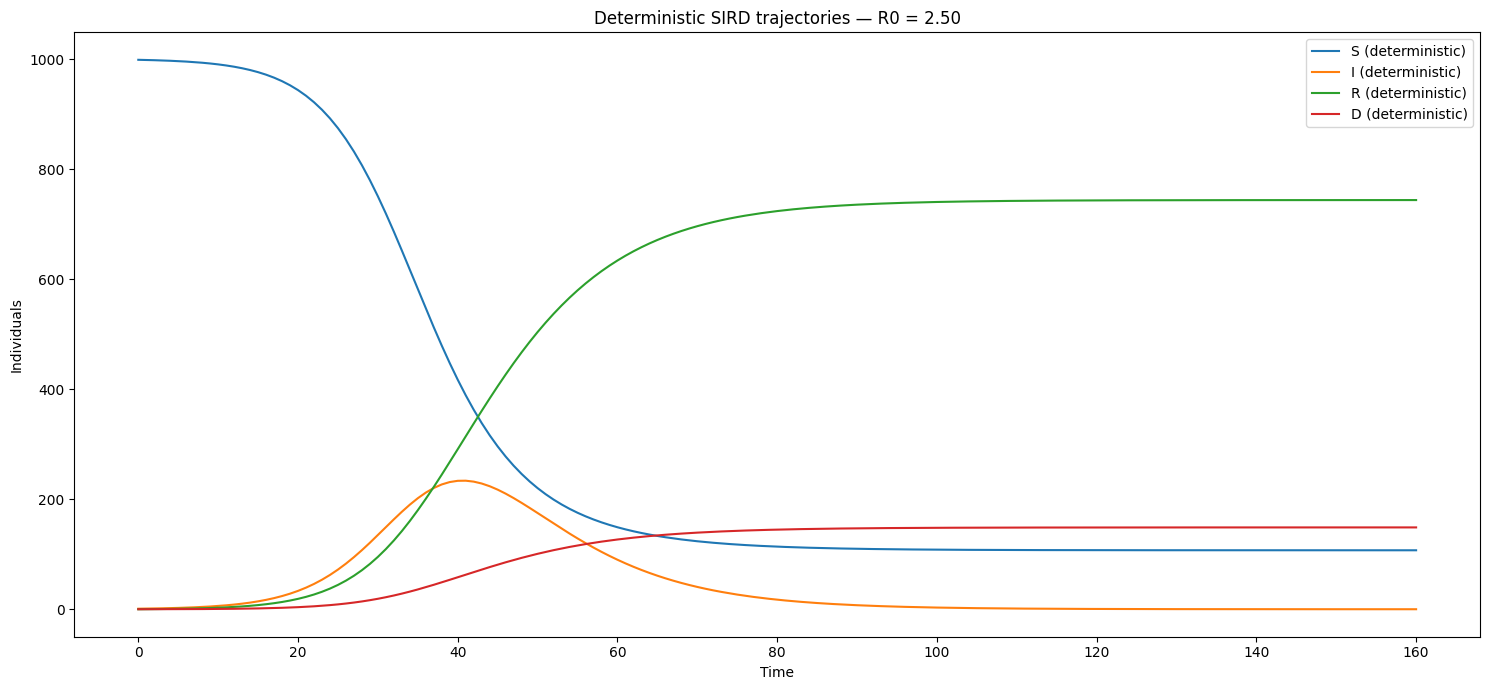

In [9]:
t_ode, X_ode = solve_sird_ode(S0, I0, R0, D0, beta, gamma, mu, N, t_max)
S_ode, I_ode, R_ode, D_ode = X_ode.T

plt.figure(figsize=(15, 7))
plt.plot(t_ode, S_ode, label="S (deterministic)")
plt.plot(t_ode, I_ode, label="I (deterministic)")
plt.plot(t_ode, R_ode, label="R (deterministic)")
plt.plot(t_ode, D_ode, label="D (deterministic)")
plt.xlabel("Time")
plt.ylabel("Individuals")
plt.title(f"Deterministic SIRD trajectories — R0 = {beta/(gamma+mu):.2f}")
plt.legend()
plt.tight_layout()
plt.show()

The deterministic trajectories show a classic epidemic pattern for the baseline parameter set (R₀ = 2.50). Starting from a single infectious individual, I(t) grows slowly at first and then increases rapidly, reaching a peak of about 250 infectious individuals around day 40. After the peak, I(t) decreases to zero as the susceptible pool is depleted.

The susceptible compartment S(t) starts very close to N and drops sharply during the growth phase of the epidemic, stabilising around 150 individuals who escape infection. 

The recovered compartment R(t) rises steeply and approaches a plateau of roughly 800 individuals, while the deaths D(t) grow more slowly and level off around 180. This is consistent with the ratio μ ⁄ (γ + μ): approximately one out of six removed individuals dies, while the others recover.

Overall, the plot provides a smooth baseline description of how the epidemic would evolve in a large, well-mixed population with these parameters. In the next subsections we will see how the stochastic model, starting from the same initial condition, can deviate from this trajectory due to random fluctuations and, in some runs, even fail to produce a large outbreak.

### 3.2 Stochastic realisation


We now simulate the baseline scenario with the stochastic SIRD model using `gillespie_sird`. Starting from the same initial condition and parameters as in the deterministic case, this produces one random epidemic trajectory driven by individual infection, recovery and death events.

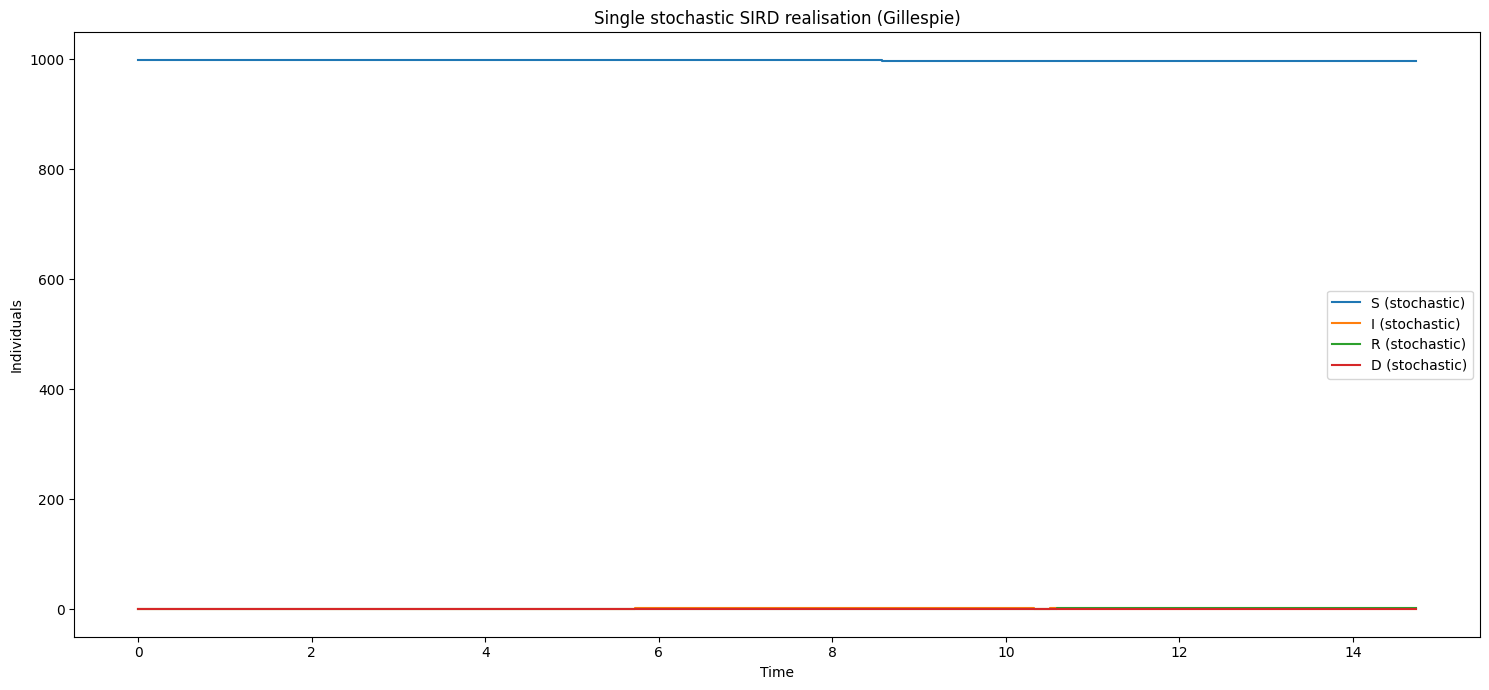

In [10]:
T_stoch, X_stoch = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
S_st, I_st, R_st, D_st = X_stoch.T

plt.figure(figsize=(15, 7))
plt.step(T_stoch, S_st, where="post", label="S (stochastic)")
plt.step(T_stoch, I_st, where="post", label="I (stochastic)")
plt.step(T_stoch, R_st, where="post", label="R (stochastic)")
plt.step(T_stoch, D_st, where="post", label="D (stochastic)")
plt.xlabel("Time")
plt.ylabel("Individuals")
plt.title("Single stochastic SIRD realisation (Gillespie)")
plt.legend()
plt.tight_layout()
plt.show()

The stochastic trajectories illustrate how the same parameter set can produce very different epidemic outcomes. 

In some realisations the curves closely resemble the deterministic solution: I(t) grows to a pronounced peak, S(t) drops sharply, and both R(t) and D(t) increase to values comparable with the deterministic final size. The evolution is, however, clearly stepwise and irregular, reflecting the fact that infections, recoveries and deaths occur as discrete random events.

In other realisations, instead, the infection dies out almost immediately: I(t) never takes off and S(t) remains essentially equal to N throughout the simulation. This is an example of **early fade-out**: even though the basic reproduction number is larger than one and the deterministic model predicts a large outbreak, stochasticity can still prevent the epidemic from establishing itself when case numbers are very low.

Every time the Gillespie simulation is rerun, a new trajectory is generated, and the outcome lies somewhere between these extremes. This run-to-run variability is precisely what the deterministic SIRD model cannot capture and motivates the ensemble analysis performed in the next subsection.

### 3.3 Ensemble of stochastic runs

To quantify the typical stochastic behaviour under the baseline parameters, we run an ensemble of simulations with `run_many` and collect n = 200 Gillespie realisations on a common time grid. From these trajectories we compute, at each time point, the mean number of infectious individuals and an empirical 95% interval. The plot below shows I(t) summarised in this way, allowing us to compare the average outbreak profile with the variability across runs.

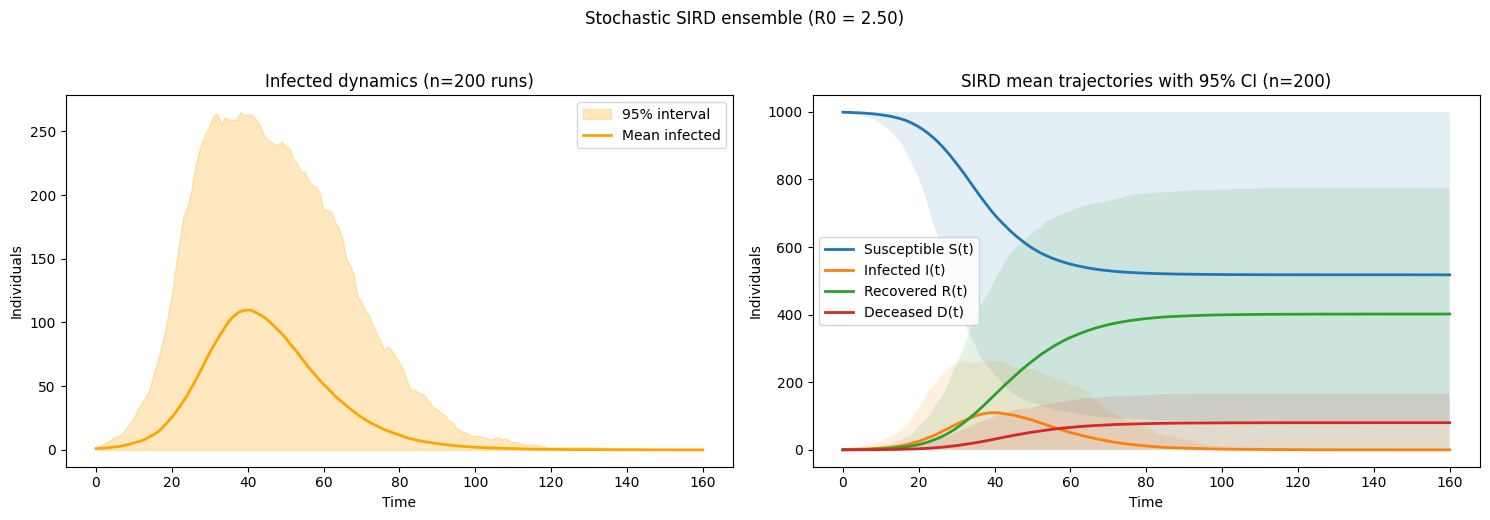

In [11]:
t_mean = many["t"]

S_mean, S_lo, S_hi = many["S"]
I_mean, I_lo, I_hi = many["I"]
R_mean, R_lo, R_hi = many["R"]
D_mean, D_lo, D_hi = many["D"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=False)

ax = axes[0]
ax.fill_between(t_mean, I_lo, I_hi, alpha=0.25, label="95% interval", color="orange")
ax.plot(t_mean, I_mean, lw=2, label="Mean infected", color="orange")
ax.set_xlabel("Time")
ax.set_ylabel("Individuals")
ax.set_title(f"Infected dynamics (n={len(many['raw']['I'])} runs)")
ax.legend()

ax = axes[1]
for mean, lo, hi, label in [
    (S_mean, S_lo, S_hi, "Susceptible S(t)"),
    (I_mean, I_lo, I_hi, "Infected I(t)"),
    (R_mean, R_lo, R_hi, "Recovered R(t)"),
    (D_mean, D_lo, D_hi, "Deceased D(t)"),
]:
    ax.fill_between(t_mean, lo, hi, alpha=0.12)
    ax.plot(t_mean, mean, lw=2, label=label)

ax.set_xlabel("Time")
ax.set_ylabel("Individuals")
ax.set_title(f"SIRD mean trajectories with 95% CI (n={len(many['raw']['I'])})")
ax.legend()

fig.suptitle(f"Stochastic SIRD ensemble (R0 = {beta/(gamma+mu):.2f})", y=1.03)
plt.tight_layout()
plt.show()

The left panel focuses on the infected compartment. The mean curve displays a smooth epidemic profile: I(t) rises from a single initial case, peaks slightly above 100 infectious individuals around day 40, and then decays to zero. The shaded 95% interval is narrow at the beginning and end of the outbreak, but becomes wide around the peak, indicating substantial variability in both peak height and timing and a non-negligible probability of early fade-out.

The right panel shows the corresponding mean trajectories and 95% intervals for all four compartments. While S(t), R(t) and D(t) exhibit relatively moderate uncertainty bands, the infected compartment clearly concentrates most of the variability: this is where stochastic effects are most visible and where the deterministic and stochastic descriptions differ the most.

## 4. Deterministic vs Stochastic dynamics

### 4.1 Infected trajectories

We now compare the deterministic prediction for the infected compartment with the behaviour of the stochastic model under the baseline parameters. Using the ensemble generated in Section 3.3, we overlay the deterministic I(t) curve with the stochastic mean and its 95% interval. This allows us to see how closely the average of many Gillespie realisations follows the ODE solution, and how large the fluctuations around it are.

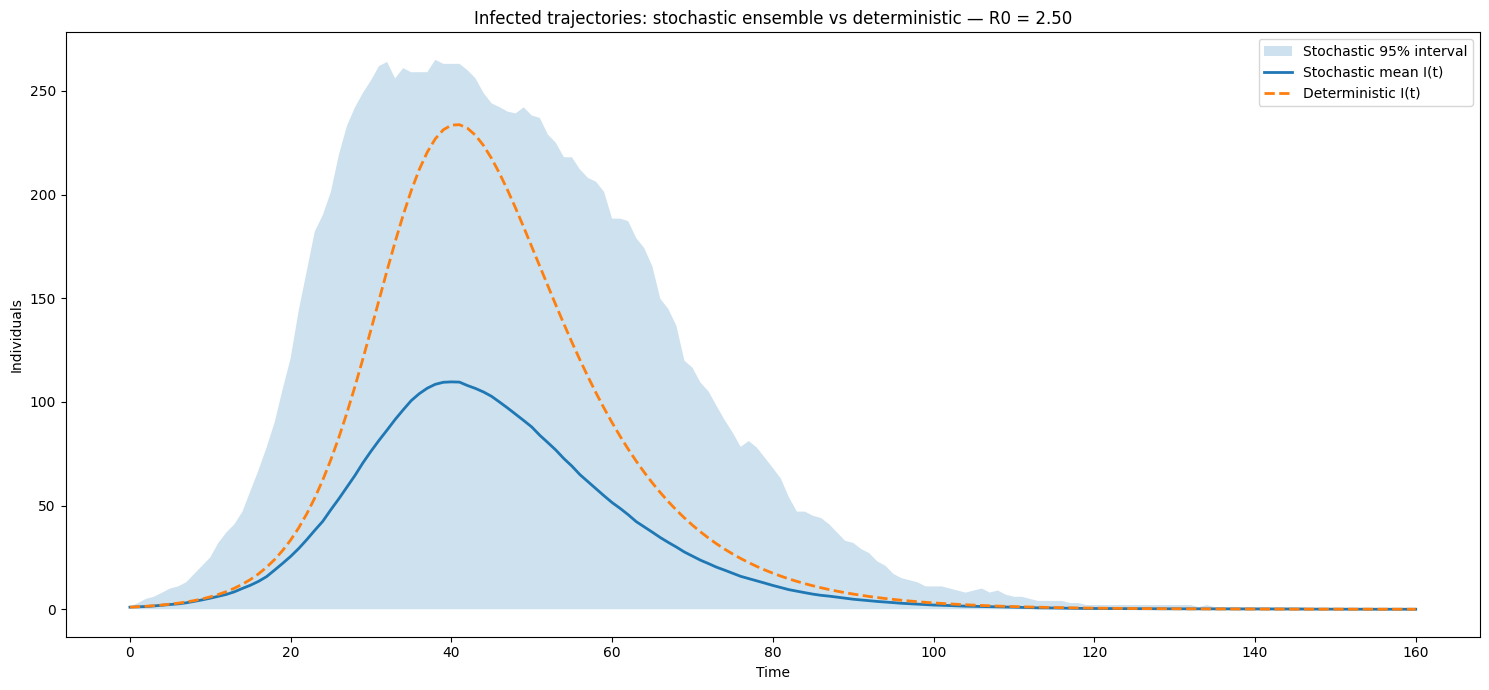

In [12]:
I_ode_on_grid = np.interp(t_mean, t_ode, I_ode)

plt.figure(figsize=(15, 7))
plt.fill_between(t_mean, I_lo, I_hi, alpha=0.22, label="Stochastic 95% interval")
plt.plot(t_mean, I_mean, lw=2, label="Stochastic mean I(t)")
plt.plot(t_mean, I_ode_on_grid, "--", lw=2, label="Deterministic I(t)")
plt.xlabel("Time")
plt.ylabel("Individuals")
plt.title(f"Infected trajectories: stochastic ensemble vs deterministic — R0 = {beta/(gamma+mu):.2f}")
plt.legend()
plt.tight_layout()
plt.show()

The deterministic I(t) (dashed line) closely matches the shape of the stochastic mean, with a peak around day 40, but it reaches a clearly higher maximum. This indicates that the ODE model tends to overestimate the peak size compared to the average behaviour of the stochastic system.

The shaded 95% interval shows that, around the peak, individual stochastic trajectories can differ substantially from both the mean and the deterministic curve. Some outbreaks remain relatively small or fade out early, pulling the mean down, whereas the deterministic model implicitly assumes that a large epidemic occurs whenever R₀ > 1. As a result, the deterministic solution is a useful reference, but it does not capture the variability or the non-negligible probability of much milder epidemics.

### 4.2 Peak comparison

To quantify the difference between the deterministic and stochastic descriptions, we compare the peak of the infected compartment in the two cases. Using the deterministic trajectory from Section 3.1 and the ensemble mean from Section 3.3, we extract the peak height and the corresponding time and compute their differences.

In [13]:
def peak_info(t, I):
    idx = int(np.argmax(I))
    return I[idx], t[idx]

peak_mean, t_peak_mean = peak_info(t_mean, I_mean)
peak_ode,  t_peak_ode  = peak_info(t_ode, I_ode)

print(f"Stochastic mean peak I: {peak_mean:.1f} at t ≈ {t_peak_mean:.1f}")
print(f"Deterministic ODE peak I: {peak_ode:.1f} at t ≈ {t_peak_ode:.1f}")
print(f"Δ peak height (ODE - mean): {peak_ode - peak_mean:.1f}")
print(f"Δ peak time   (ODE - mean): {t_peak_ode - t_peak_mean:.1f}")


Stochastic mean peak I: 109.7 at t ≈ 40.0
Deterministic ODE peak I: 233.7 at t ≈ 41.0
Δ peak height (ODE - mean): 124.1
Δ peak time   (ODE - mean): 1.0


The peak comparison shows a substantial quantitative gap between the two descriptions. The stochastic mean reaches a peak of about 110 infectious individuals at t ≈ 40, while the deterministic model peaks at about 234 at t ≈ 41. The peak times differ by only 1 day, so the timing of the outbreak is essentially the same, but the deterministic peak is more than twice as high (Δ ≈ 124 individuals).

This confirms that, for this parameter set, the deterministic SIRD model gives a good approximation of the **timing** of the epidemic but clearly overestimates its **intensity** compared with the average stochastic behaviour, where a non-negligible fraction of realisations produces smaller outbreaks or early fade-out.

### 4.3 Early fade-out and variability

Beyond the peak height and timing, the stochastic model also reveals how likely it is that the epidemic fails to take off and how long outbreaks typically last. Using the ensemble generated in Section 3.3, we estimate the probability of early fade-out and the average epidemic duration, together with other summary quantities such as final epidemic size and total deaths. These metrics complement the comparison of I(t) and highlight aspects of the dynamics that have no counterpart in the deterministic SIRD model.

In [14]:
metrics_baseline = ensemble_metrics_from_results(many, t_early=20.0)
for k, v in metrics_baseline.items():
    print(f"{k}: {v}")

peak_mean: 132.14
peak_time_mean: 22.56
attack_mean: 482.15
mortality_mean: 80.31
duration_mean: 64.04
fade_out: 0.445


For the baseline scenario, the per-trajectory metrics show that stochastic outbreaks are typically sizeable but highly variable. On average, individual simulations reach a peak of about 132 infectious individuals around t ≈ 23, with a mean final epidemic size of ≈ 482 individuals and about 80 deaths. The mean duration is roughly 64 days, so once an epidemic takes off it tends to persist for several weeks.

The early fade-out probability is ≈ 0.45 for the threshold t ≤ 20, meaning that in almost half of the runs the infection has already disappeared by day 20. This also explains why the peak of the ensemble mean I(t) (≈ 110 around t ≈ 40) is lower and later than the mean of the individual peaks: mathematically,
\begin{aligned}
\max_t \mathbb{E}[I(t)] \neq \mathbb{E}\left[\max_t I(t)\right]
\end{aligned}
The mean curve is pulled down and smeared out by many short-lived outbreaks, so its maximum occurs later and is smaller. In contrast, the per-trajectory metrics \(\max_t I(t)\) are computed on each run before averaging, and therefore reflect more directly how large and how early successful epidemics tend to be.

## 5. Parameter Analysis

### 5.1 Effect of infection rate β

We first study how the infection rate β influences the behaviour of the stochastic SIRD model. Keeping all other parameters and initial conditions fixed, we vary β over a small range around the baseline value and, for each value, run an ensemble of Gillespie simulations. From the resulting trajectories we extract ensemble statistics such as the mean infection peak, the mean time to peak and the probability of early fade-out, and we summarise them as functions of β.

In [15]:
def metrics_for_beta(beta_value, n_runs=200, seed=42, t_early=20.0):
    
    beta_orig = beta
    globals()["beta"] = beta_value

    results = run_many(n_runs=n_runs, t_max=t_max, seed=seed)
    metrics = ensemble_metrics_from_results(results, t_early=t_early)

    globals()["beta"] = beta_orig

    metrics["beta"] = beta_value
    metrics["R0"]   = beta_value / (gamma + mu)

    return metrics

In [16]:
beta_list = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
summary_beta = []

for b in beta_list:
    m = metrics_for_beta(b, n_runs=200, seed=42, t_early=20.0)
    summary_beta.append(m)

df_beta = pd.DataFrame(summary_beta)
df_beta

,peak_mean,peak_time_mean,attack_mean,mortality_mean,duration_mean,fade_out,beta,R0
0,2.325,5.935,5.205,0.950,15.67,0.765,0.10,0.833333
1,7.850,20.345,46.775,7.620,34.31,0.710,0.15,1.250000
2,38.885,27.920,232.090,38.135,58.54,0.595,0.20,1.666667
3,84.065,25.400,375.975,62.630,63.90,0.510,0.25,2.083333
4,132.140,22.560,482.150,80.310,64.04,0.445,0.30,2.500000
5,183.265,21.310,574.940,96.115,65.86,0.380,0.35,2.916667
6,228.200,19.475,633.270,105.985,64.52,0.340,0.40,3.333333
7,266.940,17.570,672.240,112.505,62.57,0.310,0.45,3.750000
8,297.935,16.085,693.445,116.150,60.42,0.295,0.50,4.166667


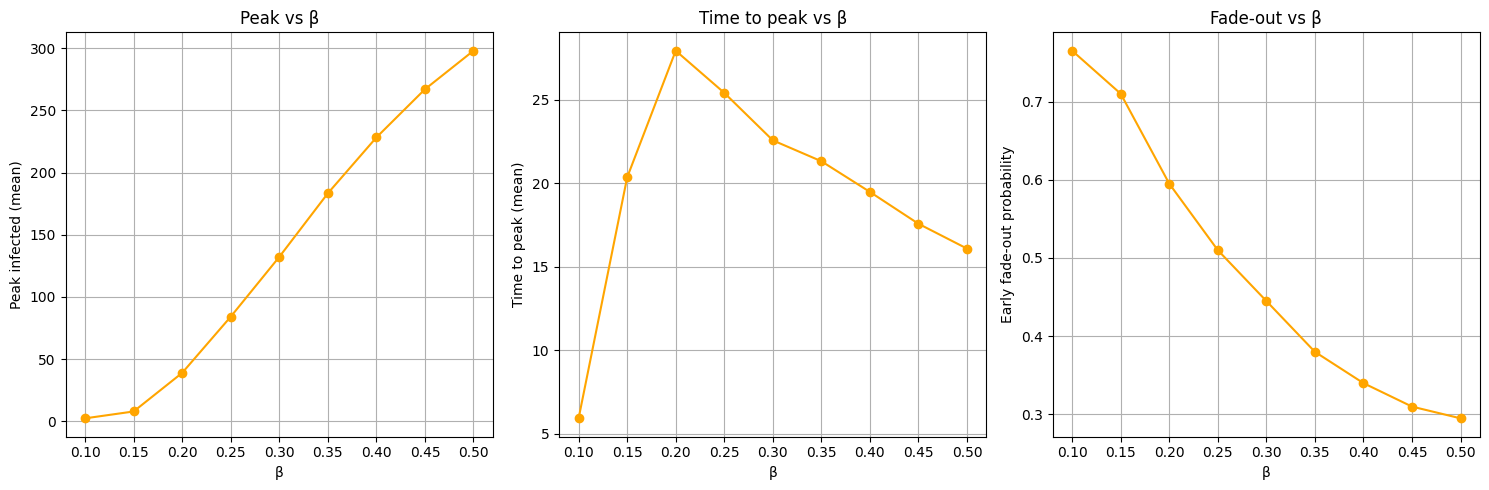

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(df_beta["beta"], df_beta["peak_mean"], marker="o", color="orange")
axes[0].set_xlabel("β")
axes[0].set_ylabel("Peak infected (mean)")
axes[0].set_title("Peak vs β")
axes[0].grid(True)

axes[1].plot(df_beta["beta"], df_beta["peak_time_mean"], marker="o", color="orange")
axes[1].set_xlabel("β")
axes[1].set_ylabel("Time to peak (mean)")
axes[1].set_title("Time to peak vs β")
axes[1].grid(True)

axes[2].plot(df_beta["beta"], df_beta["fade_out"], marker="o", color="orange")
axes[2].set_xlabel("β")
axes[2].set_ylabel("Early fade-out probability")
axes[2].set_title("Fade-out vs β")
axes[2].grid(True)

plt.tight_layout()
plt.show()

The three panels show a clear and coherent dependence on β over a wide range.
 
In the left plot, the mean peak number of infectious individuals increases steeply and almost linearly for larger β, from about 2 cases at β = 0.10 to nearly 300 at β = 0.50. Higher transmission strongly amplifies the typical epidemic size.

The middle panel indicates that the mean time to peak first increases, reaching about 28 days around β = 0.20 (R₀ ≈ 1.67), and then decreases as β grows further: for very high β, outbreaks are both larger and faster, with peaks occurring around 16–20 days.

The right panel shows that early fade-out becomes progressively less likely as β increases. The probability that the infection has died out by t = 20 drops from about 0.77 at β = 0.10 to below 0.30 at β = 0.50. Overall, higher β makes epidemics more intense, earlier, and less likely to disappear at low case numbers.

### 5.2 Effects of population size N

We next investigate how the population size N affects the stochastic SIRD dynamics. Keeping β, γ, μ and the initial fraction of infectious individuals fixed, we vary N over a wide range around the baseline value and, for each N, simulate an ensemble of Gillespie trajectories. From these ensembles we compute summary statistics such as mean peak size, peak variance and early fade-out probability, in order to assess how stochastic variability decreases as the system becomes larger.

In [18]:
def metrics_for_N(N_value, n_runs=200, seed=42, t_early=20.0):

    S0_new = N_value - (I0 + R0 + D0)

    rng_master = np.random.default_rng(seed)
    t_grid = np.arange(0, int(t_max) + 1, 1.0)

    S_runs, I_runs, R_runs, D_runs = [], [], [], []

    for _ in range(n_runs):
        rng = np.random.default_rng(rng_master.integers(0, 2**31 - 1))
        T, X = gillespie_sird(S0_new, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=rng)
        Xg = step_hold_resample(T, X, t_grid)
        S_runs.append(Xg[:, 0])
        I_runs.append(Xg[:, 1])
        R_runs.append(Xg[:, 2])
        D_runs.append(Xg[:, 3])

    S = np.vstack(S_runs)
    I = np.vstack(I_runs)
    R = np.vstack(R_runs)
    D = np.vstack(D_runs)

    results = {
        "t": t_grid,
        "raw": dict(S=S, I=I, R=R, D=D),
    }

    metrics = ensemble_metrics_from_results(results, t_early=t_early)

    peak_vals = I.max(axis=1)
    peak_var = float(peak_vals.var())

    metrics["N"] = N_value
    metrics["peak_var"] = peak_var

    return metrics

In [19]:
N_list = [200, 500, 800, 1000, 1500, 2000, 3000, 5000, 8000]
summary_N = []

for Nv in N_list:
    summary_N.append(metrics_for_N(Nv, n_runs=200, seed=42, t_early=20.0))

df_N = pd.DataFrame(summary_N)
df_N

,peak_mean,peak_time_mean,attack_mean,mortality_mean,duration_mean,fade_out,N,peak_var
0,28.390,17.725,96.755,15.850,49.080,0.445,200,666.287900
1,67.385,20.330,241.700,39.415,58.185,0.445,500,3842.156775
2,107.060,21.735,386.535,64.245,62.305,0.445,800,9726.986400
3,132.140,22.560,482.150,80.310,64.040,0.445,1000,14872.430400
4,196.895,23.845,730.735,122.365,67.895,0.440,1500,32354.083975
5,259.685,24.775,971.470,162.090,70.265,0.440,2000,56371.005775
6,387.020,25.950,1457.565,241.770,73.560,0.440,3000,124997.419600
7,641.420,27.665,2430.715,403.955,79.545,0.440,5000,343642.153600
8,1024.635,28.945,3891.295,646.845,82.195,0.440,8000,877830.511775


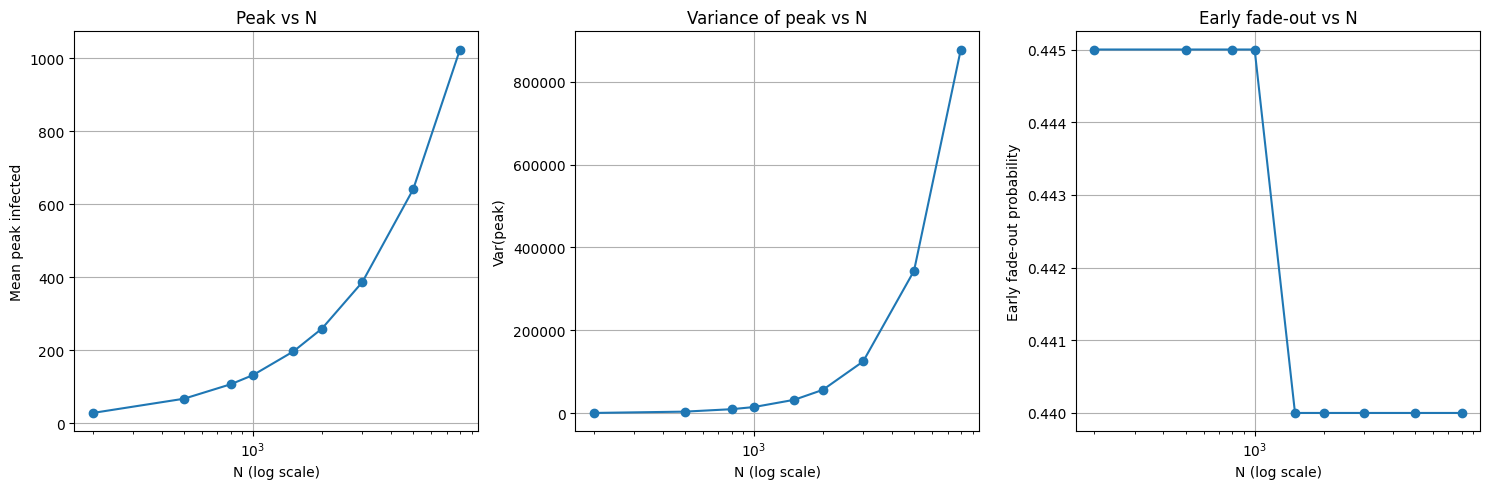

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(df_N["N"], df_N["peak_mean"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("N (log scale)")
axes[0].set_ylabel("Mean peak infected")
axes[0].set_title("Peak vs N")
axes[0].grid(True)

axes[1].plot(df_N["N"], df_N["peak_var"], marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("N (log scale)")
axes[1].set_ylabel("Var(peak)")
axes[1].set_title("Variance of peak vs N")
axes[1].grid(True)

axes[2].plot(df_N["N"], df_N["fade_out"], marker="o")
axes[2].set_xscale("log")
axes[2].set_xlabel("N (log scale)")
axes[2].set_ylabel("Early fade-out probability")
axes[2].set_title("Early fade-out vs N")
axes[2].grid(True)

plt.tight_layout()
plt.show()

The left panel shows that the mean peak number of infectious individuals increases strongly with N. For fixed β, γ and μ, the peak grows from about 30 infected at N = 200 to just above 1000 at N = 8000, i.e. roughly proportionally to the population size. This reflects the fact that, once an epidemic takes off, a similar fraction of the population becomes infected, so larger populations naturally generate larger absolute peaks.

In the middle panel, the variance of the peak also increases sharply with N, spanning almost three orders of magnitude over the explored range. However, this growth is slower than quadratic in N, so the *relative* variability (standard deviation divided by the mean peak) decreases: as the system becomes larger, stochastic fluctuations are averaged out and the epidemic behaves more “deterministically”.

The right panel shows that the early fade-out probability is almost independent of N in this range, remaining close to 0.44. This is consistent with the idea that early extinction is mainly determined by the initial branching phase of the infection, which depends on β, γ and μ but is only weakly affected by the total population size when N is already moderately large.

### 5.3 Effects of mortality rate μ

Finally, we analyse how the disease-induced mortality μ affects the epidemic dynamics. Keeping β, γ, N and the initial condition fixed, we vary μ over a broad range. For each value of μ we run an ensemble of stochastic simulations and compute summary statistics such as the mean peak number of infectious individuals, the mean final epidemic size and the mean number of deaths. This allows us to explore how increasing lethality modifies both the size of the epidemic and its impact in terms of mortality.

In [21]:
def metrics_for_mu(mu_value, n_runs=200, seed=42, t_early=20.0):

    mu_orig = mu
    globals()["mu"] = mu_value

    results = run_many(n_runs=n_runs, t_max=t_max, seed=seed)
    metrics = ensemble_metrics_from_results(results, t_early=t_early)

    globals()["mu"] = mu_orig

    metrics["mu"] = mu_value
    metrics["R0"] = beta / (gamma + mu_value)

    return metrics

In [22]:
mu_list = [0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.15, 0.20, 0.25]
summary_mu = []

for mv in mu_list:
    summary_mu.append(metrics_for_mu(mv, n_runs=200, seed=42, t_early=20.0))

df_mu = pd.DataFrame(summary_mu)
df_mu

,peak_mean,peak_time_mean,attack_mean,mortality_mean,duration_mean,fade_out,mu,R0
0,157.605,23.325,523.685,47.735,67.930,0.415,0.01,2.727273
1,132.140,22.560,482.150,80.310,64.040,0.445,0.02,2.500000
2,91.930,21.470,399.490,114.005,56.200,0.505,0.04,2.142857
3,60.330,19.745,309.365,116.085,47.000,0.575,0.06,1.875000
4,38.505,18.485,235.820,104.465,43.290,0.620,0.08,1.666667
5,24.520,17.525,178.370,88.890,39.055,0.665,0.10,1.500000
6,6.315,9.970,46.215,27.925,19.560,0.800,0.15,1.200000
7,3.050,3.675,11.735,7.985,8.310,0.890,0.20,1.000000
8,2.200,2.430,5.675,4.315,5.450,0.935,0.25,0.857143


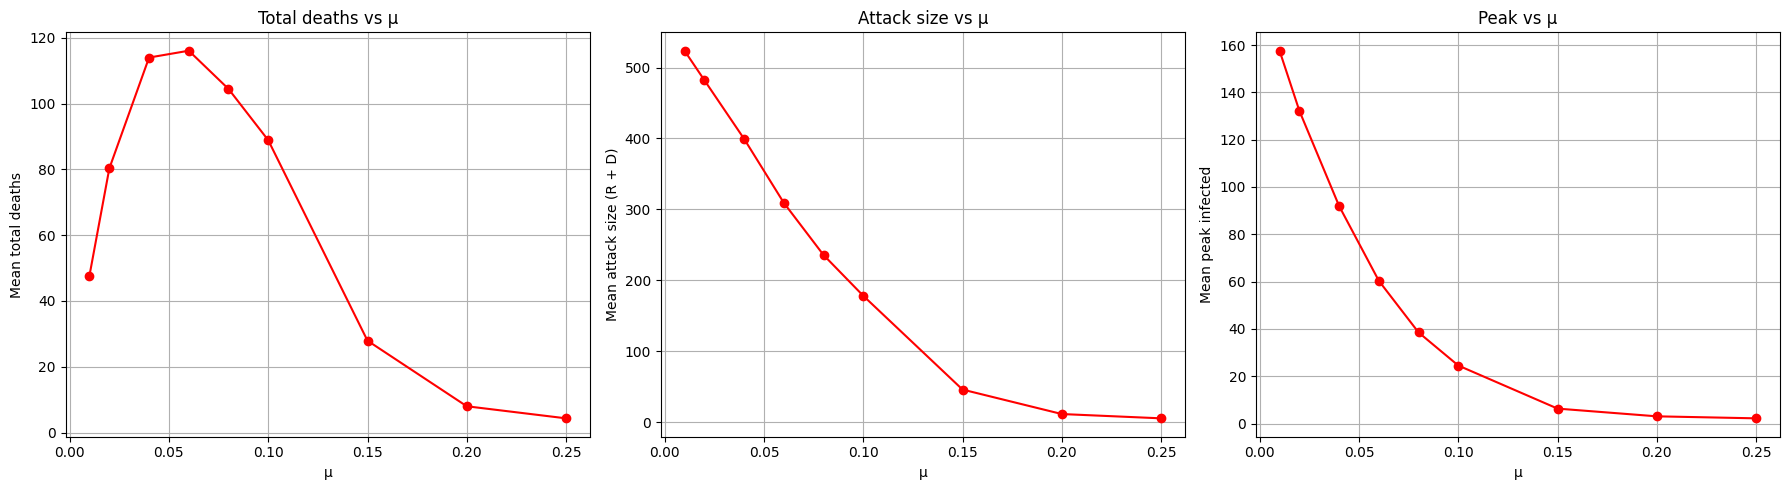

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df_mu["mu"], df_mu["mortality_mean"], marker="o",color="red")
axes[0].set_xlabel("μ")
axes[0].set_ylabel("Mean total deaths")
axes[0].set_title("Total deaths vs μ")
axes[0].grid(True)

axes[1].plot(df_mu["mu"], df_mu["attack_mean"], marker="o", color="red")
axes[1].set_xlabel("μ")
axes[1].set_ylabel("Mean attack size (R + D)")
axes[1].set_title("Attack size vs μ")
axes[1].grid(True)

axes[2].plot(df_mu["mu"], df_mu["peak_mean"], marker="o", color="red")
axes[2].set_xlabel("μ")
axes[2].set_ylabel("Mean peak infected")
axes[2].set_title("Peak vs μ")
axes[2].grid(True)

plt.tight_layout()
plt.show()

The effect of μ is clearly non-trivial. In the left panel, the mean total number of deaths is maximal for intermediate values of μ, around μ = 0.04–0.06, and then decreases both for smaller and larger μ. This reflects a trade-off: increasing μ makes the disease more lethal but at the same time reduces the basic reproduction number R₀. For very high μ the epidemic struggles to spread, so the total number of infections (and therefore deaths) becomes small again.

The middle panel shows that the mean attack size (R + D) decreases monotonically with μ: from about 520 individuals at μ = 0.01 down to fewer than 10 at μ = 0.25. As μ increases, R₀ drops from ≈ 2.73 to below 1, and a growing fraction of simulations produces only minor outbreaks.

In the right panel, the mean peak number of infectious individuals also decreases sharply with μ, from more than 150 at μ = 0.01 to just a few individuals at μ ≥ 0.20. Overall, higher mortality reduces both the size and the peak of the epidemic, and the largest mortality burden is obtained at intermediate μ, where the disease is still contagious enough to infect a large portion of the population.

### 5.4 Joint effect of β and μ

To visualise the combined effect of infection rate β and mortality μ, we vary both parameters simultaneously and summarise the outcome by the mean peak number of infectious individuals. For each pair (β, μ) in a grid around the baseline values we run an ensemble of stochastic simulations, compute the peak of I(t) for every run, and take the average. The resulting values are displayed as a heatmap in the (β, μ) plane, highlighting regions corresponding to small, moderate and very large epidemics.

In [24]:
def peak_matrix_beta_mu(beta_vals, mu_vals, n_runs=150, seed=42):

    beta_orig, mu_orig = beta, mu
    M = np.zeros((len(beta_vals), len(mu_vals)))

    for i, b in enumerate(beta_vals):
        for j, m in enumerate(mu_vals):
            globals()["beta"] = b
            globals()["mu"] = m
            results = run_many(n_runs=n_runs, t_max=t_max, seed=seed)
            I = results["raw"]["I"]
            peaks = I.max(axis=1)
            M[i, j] = peaks.mean()

    globals()["beta"] = beta_orig
    globals()["mu"] = mu_orig

    return M

In [25]:
beta_grid = [0.10, 0.20, 0.30, 0.40, 0.50]
mu_grid   = [0.01, 0.04, 0.08, 0.15, 0.25]

peak_mat = peak_matrix_beta_mu(beta_grid, mu_grid, n_runs=150, seed=42)

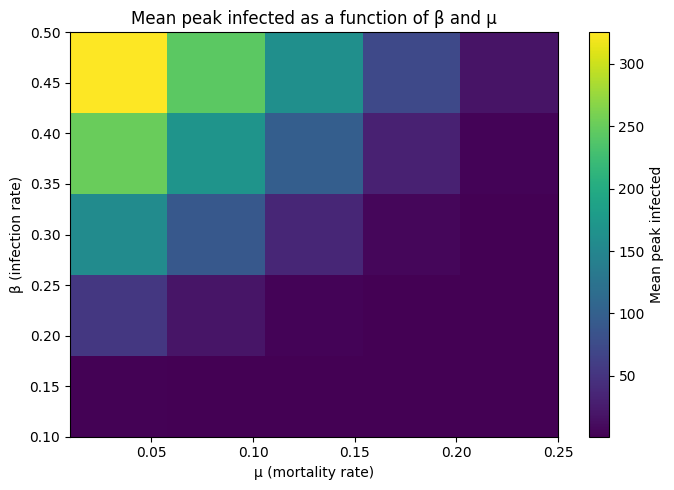

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    peak_mat,
    origin="lower",
    aspect="auto",
    extent=[min(mu_grid), max(mu_grid), min(beta_grid), max(beta_grid)]
)

ax.set_xlabel("μ (mortality rate)")
ax.set_ylabel("β (infection rate)")
ax.set_title("Mean peak infected as a function of β and μ")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Mean peak infected")

plt.tight_layout()
plt.show()

The heatmap summarises how the mean infection peak depends jointly on β and μ. As expected, the largest peaks occur in the top-left region, where β is high and μ is small: for example, β = 0.5 and μ = 0.01 produce average peaks above 300 infectious individuals. Moving to the right (increasing μ) or downward (decreasing β) the colour intensity fades, indicating progressively smaller outbreaks.

The lower-right part of the diagram is almost flat at zero, corresponding to combinations where R₀ is close to or below 1 and the epidemic typically fails to establish itself. Overall, the heatmap clearly shows the transition from parameter regimes with negligible outbreaks to regimes with large epidemics, and how this transition is controlled by the balance between transmission β and mortality μ.

## 6. Time-dependent infection rate β(t)

### 6.1 Deterministic with an intervention on β(t)

So far we have assumed a constant infection rate β. To mimic the effect of control measures or behavioural changes, we now consider a time-dependent infection rate β(t) that undergoes a step change at a given intervention time tᵢₙₜ. In this subsection we modify the deterministic SIRD model to include β(t) and compare three scenarios: the constant-β baseline, a 50% reduction and a 50% increase of β after tᵢₙₜ.

In [27]:
def beta_step(t, beta_before, beta_after, t_int):
    return beta_before if t < t_int else beta_after

In [28]:
def sird_ode_time_dependent(t, y, beta_before, beta_after, t_int, gamma, mu, N):
    S, I, R, D = y
    beta_t = beta_step(t, beta_before, beta_after, t_int)

    infection_flow = beta_t * S * I / N
    removal_flow   = (gamma + mu) * I

    dSdt = -infection_flow
    dIdt =  infection_flow - removal_flow
    dRdt =  gamma * I
    dDdt =  mu * I

    return [dSdt, dIdt, dRdt, dDdt]

In [29]:
def solve_sird_ode_time_dependent(
    S0, I0, R0, D0,
    beta_before, beta_after, t_int,
    gamma, mu, N,
    t_max
):
    y0 = [S0, I0, R0, D0]

    sol = solve_ivp(
        sird_ode_time_dependent,
        t_span=(0, t_max),
        y0=y0,
        args=(beta_before, beta_after, t_int, gamma, mu, N),
        dense_output=True,
        rtol=1e-7,
        atol=1e-9,
    )

    t_dense = np.linspace(0, t_max, int(t_max) + 1)
    S, I, R, D = sol.sol(t_dense)
    X_dense = np.vstack([S, I, R, D]).T

    return t_dense, X_dense

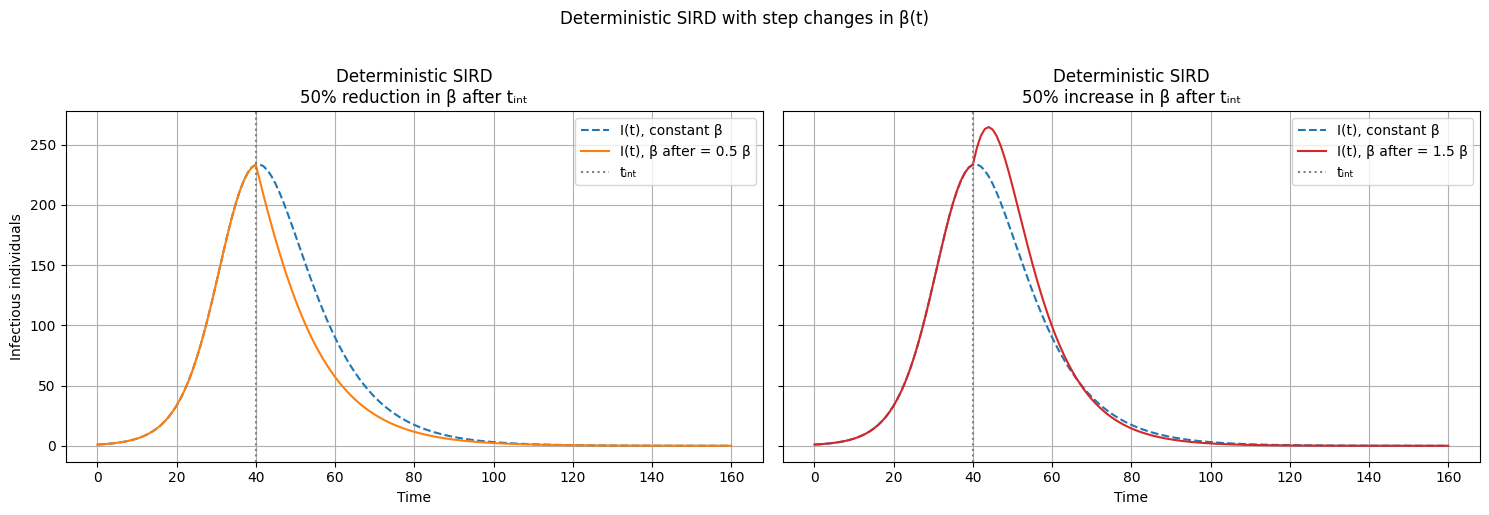

In [30]:
t_ode, X_ode = solve_sird_ode(S0, I0, R0, D0, beta, gamma, mu, N, t_max)
S_ode, I_ode, R_ode, D_ode = X_ode.T

t_int = 40.0
beta_before = beta
beta_after_minus = 0.5 * beta_before   
beta_after_plus  = 1.5 * beta_before  

t_td_minus, X_td_minus = solve_sird_ode_time_dependent(
    S0, I0, R0, D0,
    beta_before, beta_after_minus, t_int,
    gamma, mu, N,
    t_max,
)
S_m, I_m, R_m, D_m = X_td_minus.T

t_td_plus, X_td_plus = solve_sird_ode_time_dependent(
    S0, I0, R0, D0,
    beta_before, beta_after_plus, t_int,
    gamma, mu, N,
    t_max,
)
S_p, I_p, R_p, D_p = X_td_plus.T

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

ax = axes[0]
ax.plot(t_ode, I_ode, "--", label="I(t), constant β")
ax.plot(t_td_minus, I_m, "-", label="I(t), β after = 0.5 β")
ax.axvline(t_int, color="grey", ls=":", label="tᵢₙₜ")
ax.set_xlabel("Time")
ax.set_ylabel("Infectious individuals")
ax.set_title("Deterministic SIRD\n50% reduction in β after tᵢₙₜ")
ax.legend()
ax.grid(True)

ax = axes[1]
ax.plot(t_ode, I_ode, "--", label="I(t), constant β")
ax.plot(t_td_plus, I_p, "-", color="tab:red", label="I(t), β after = 1.5 β")
ax.axvline(t_int, color="grey", ls=":", label="tᵢₙₜ")
ax.set_xlabel("Time")
ax.set_title("Deterministic SIRD\n50% increase in β after tᵢₙₜ")
ax.legend()
ax.grid(True)

fig.suptitle("Deterministic SIRD with step changes in β(t)", y=1.02)
plt.tight_layout()
plt.show()

The two panels show how different step changes in β(t) after the intervention time tᵢₙₜ = 40 affect the deterministic infected trajectory. In both cases the curves coincide up to tᵢₙₜ, because β is unchanged, and the peak occurs essentially at the same time and with very similar height.

In the left panel, a 50% reduction of β after tᵢₙₜ causes I(t) to decay much faster than in the constant-β baseline: the tail of the epidemic is strongly shortened and the total number of infections after the intervention is reduced. 

In the right panel, a 50% increase of β has the opposite effect: after tᵢₙₜ the decline of I(t) is slower and the tail becomes longer, leading to a larger cumulative number of infections. 

Overall, late interventions mainly modify the duration and final size of the outbreak, while leaving the peak almost unchanged.

### 6.2 Stochastic SIRD with an intervention on β(t)

We now introduce the same step changes in β(t) in the stochastic SIRD model. Starting from the baseline configuration, we compare three ensembles of Gillespie simulations: one with constant β, one where β is reduced by 50% after tᵢₙₜ = 40, and one where β is increased by 50% at the same time. For each scenario we compute the mean infected trajectory and its 95% empirical interval, in order to assess how late strengthening or weakening of transmission influences the average outbreak and its variability.

In [31]:
def gillespie_sird_time_dependent(
    S0, I0, R0, D0,
    beta_before, beta_after, t_int,
    gamma, mu, t_max=np.inf, rng=None
):
    if rng is None:
        rng = np.random.default_rng()

    N = S0 + I0 + R0 + D0
    t = 0.0
    S, I, R, D = int(S0), int(I0), int(R0), int(D0)

    T = [t]
    X = [(S, I, R, D)]

    while t < t_max:
        beta_t = beta_step(t, beta_before, beta_after, t_int)

        a1 = beta_t * S * I / N  
        a2 = gamma * I            
        a3 = mu * I             
        a0 = a1 + a2 + a3

        if a0 <= 0.0:
            break

        tau = rng.exponential(1.0 / a0)

        if t + tau > t_max:
            t = float(t_max)
            T.append(t)
            X.append((S, I, R, D))
            break

        t += tau

        r = rng.random() * a0
        if r < a1:
            if S > 0:
                S -= 1
                I += 1
        elif r < a1 + a2:
            if I > 0:
                I -= 1
                R += 1
        else:
            if I > 0:
                I -= 1
                D += 1

        T.append(t)
        X.append((S, I, R, D))

        if I == 0:
            break

    return np.array(T, dtype=float), np.array(X, dtype=int)

In [32]:
def run_many_intervention(
    n_runs=200,
    t_max=t_max,
    seed=42,
    beta_before=beta,
    beta_after=None,
    t_int=40.0,
):
    if beta_after is None:
        beta_after = 0.5 * beta_before

    rng_master = np.random.default_rng(seed)
    t_grid = np.arange(0, int(t_max) + 1, 1.0)

    S_list, I_list, R_list, D_list = [], [], [], []

    for _ in range(n_runs):
        rng = np.random.default_rng(rng_master.integers(0, 2**31 - 1))
        T, X = gillespie_sird_time_dependent(
            S0, I0, R0, D0,
            beta_before, beta_after, t_int,
            gamma, mu,
            t_max=t_max,
            rng=rng,
        )
        Xg = step_hold_resample(T, X, t_grid)
        S_list.append(Xg[:, 0])
        I_list.append(Xg[:, 1])
        R_list.append(Xg[:, 2])
        D_list.append(Xg[:, 3])

    S_raw = np.vstack(S_list)
    I_raw = np.vstack(I_list)
    R_raw = np.vstack(R_list)
    D_raw = np.vstack(D_list)

    def mean_ci(arr):
        mean = arr.mean(axis=0)
        lo = np.quantile(arr, 0.025, axis=0)
        hi = np.quantile(arr, 0.975, axis=0)
        return mean, lo, hi

    S_stats = mean_ci(S_raw)
    I_stats = mean_ci(I_raw)
    R_stats = mean_ci(R_raw)
    D_stats = mean_ci(D_raw)

    results = {
        "t": t_grid,
        "S": S_stats,
        "I": I_stats,
        "R": R_stats,
        "D": D_stats,
        "raw": {
            "S": S_raw,
            "I": I_raw,
            "R": R_raw,
            "D": D_raw,
        },
    }
    return results

In [33]:
t_base = many["t"]
I_mean_base, I_lo_base, I_hi_base = many["I"]

t_int = 40.0
beta_before = beta

many_minus = run_many_intervention(
    n_runs=200,
    t_max=t_max,
    seed=42,
    beta_before=beta_before,
    beta_after=0.5 * beta_before,
    t_int=t_int,
)

many_plus = run_many_intervention(
    n_runs=200,
    t_max=t_max,
    seed=123,  
    beta_before=beta_before,
    beta_after=1.5 * beta_before,
    t_int=t_int,
)

t_minus = many_minus["t"]
I_mean_minus, I_lo_minus, I_hi_minus = many_minus["I"]

t_plus = many_plus["t"]
I_mean_plus, I_lo_plus, I_hi_plus = many_plus["I"]

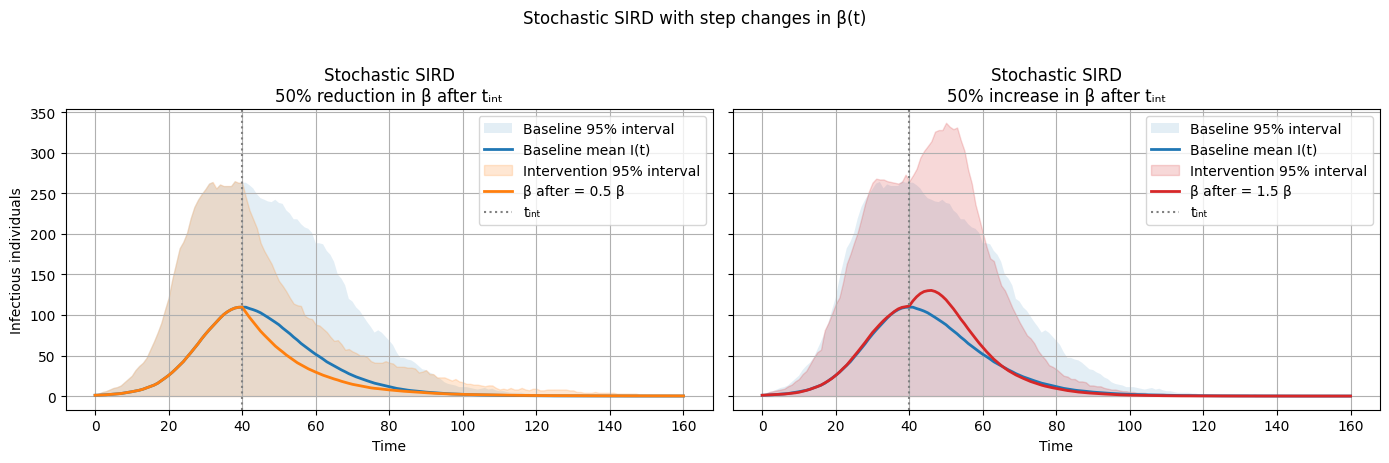

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

ax = axes[0]
ax.fill_between(t_base, I_lo_base, I_hi_base, alpha=0.12, label="Baseline 95% interval")
ax.plot(t_base, I_mean_base, lw=2, label="Baseline mean I(t)")
ax.fill_between(t_minus, I_lo_minus, I_hi_minus, alpha=0.18, color="tab:orange",
                label="Intervention 95% interval")
ax.plot(t_minus, I_mean_minus, lw=2, color="tab:orange", label="β after = 0.5 β")
ax.axvline(t_int, color="grey", ls=":", label="tᵢₙₜ")
ax.set_xlabel("Time")
ax.set_ylabel("Infectious individuals")
ax.set_title("Stochastic SIRD\n50% reduction in β after tᵢₙₜ")
ax.legend()
ax.grid(True)

ax = axes[1]
ax.fill_between(t_base, I_lo_base, I_hi_base, alpha=0.12, label="Baseline 95% interval")
ax.plot(t_base, I_mean_base, lw=2, label="Baseline mean I(t)")
ax.fill_between(t_plus, I_lo_plus, I_hi_plus, alpha=0.18, color="tab:red",
                label="Intervention 95% interval")
ax.plot(t_plus, I_mean_plus, lw=2, color="tab:red", label="β after = 1.5 β")
ax.axvline(t_int, color="grey", ls=":", label="tᵢₙₜ")
ax.set_xlabel("Time")
ax.set_title("Stochastic SIRD\n50% increase in β after tᵢₙₜ")
ax.legend()
ax.grid(True)

fig.suptitle("Stochastic SIRD with step changes in β(t)", y=1.02)
plt.tight_layout()
plt.show()

The stochastic ensembles mirror the deterministic behaviour while revealing the effect of randomness. In both panels the baseline and intervention trajectories are almost identical before tᵢₙₜ = 40, and the mean peaks occur at roughly the same time and height.

In the left panel, when β is reduced by 50% after tᵢₙₜ, the mean infected curve drops more rapidly than in the baseline and the 95% interval collapses earlier, indicating fewer infections and less variability in the late phase of the outbreak. 

In the right panel, a 50% increase in β has the opposite effect: the decline of I(t) is slower, the tail of the epidemic is longer, and the 95% interval remains wide for a longer time, reflecting a larger and more uncertain total burden. 

As in the deterministic case, late changes in β mainly affect the tail and cumulative size of the epidemic rather than the peak itself.

## 7. Discussion and conclusions

The joint analysis of deterministic and stochastic SIRD dynamics leads to a few clear take-home messages.

**First**, the deterministic model is reliable for predicting **when** an epidemic will peak but not **how large** it will be. In our baseline setting the deterministic and stochastic peaks occur at almost the same time, yet the deterministic peak is more than twice as high as the average stochastic one. This discrepancy reflects the fact that many stochastic realisations remain small or fade out early, so that
\begin{equation}
\max_t \mathrm{E}[I(t)] \neq \mathrm{E}\!\left[\max_t I(t)\right].
\end{equation}
In practice, this means that using only the deterministic peak to size healthcare capacity can be overly conservative, but using it to rule out the possibility of small outbreaks is misleading.

**Second**, the role of system size is essentially to control how “deterministic” the epidemic appears. As N increases, the absolute peak and its variance grow, but the relative fluctuations shrink and individual trajectories cluster tightly around the deterministic curve. For large populations, deterministic models are therefore a good approximation for aggregate quantities, whereas for smaller populations stochastic variability is intrinsic and cannot be ignored.

**Third**, the parameter exploration clarifies how different control levers act:
- Increasing β pushes the system deep into the supercritical regime: outbreaks become almost unavoidable, peaks grow rapidly and occur earlier, and early fade-out becomes rare.
- Increasing μ has a non-monotone effect on total deaths. Lethality by itself does not guarantee a larger burden: beyond a certain point, higher μ reduces R₀, the epidemic cannot spread efficiently and the number of deaths falls because there are too few infections.
These observations highlight that assessing risk requires considering both **transmissibility** and **lethality**, not just one of them in isolation.

**Lastly**, the experiments with a stepwise β(t) show that **timing** matters as much as **strength** for interventions. When β is changed only after the epidemic is close to its peak, even a 50% reduction has little effect on peak height and mainly shortens the tail and reduces the final size. Conversely, increasing β at the same late time prolongs the epidemic and increases cumulative cases without dramatically shifting the peak. This suggests that strong late measures can still reduce total burden, but they are not an effective tool for avoiding peak stress on the system; early action would be required for that, a scenario that could be studied by shifting tᵢₙₜ in the same framework.

Overall, the study illustrates when deterministic SIRD models are informative and when a fully stochastic description is necessary. Deterministic equations capture average trends and thresholds, while stochastic simulations are indispensable for quantifying extinction probabilities, variability in epidemic size, and the impact of interventions in regimes where chance plays a major role.